## H2 - Age and Attempts to Success

Younger clients require fewer attempts to successfully
complete the process than older clients.

### Methodology

We consider a process successful when:

- The session starts at the 'start' step.
- The session ends at the 'confirm' step.
- The session takes 360 seconds or less.

Each session (visit_id) is considered one attempt.

We organize the sessions by date and time for each client
to find how many attempts they needed to succeed for
the first time in our dataset.

We do not count any attempts after the first successful
session.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
sessions_master = pd.read_csv('../data/clean/sessions_data_master.csv')
clients_data = pd.read_csv('../data/raw/cleaned_client_data.csv')
web_data = pd.read_csv("../data/raw/cleaned_web_data.csv")

clients_data = clients_data.drop(columns=["Unnamed: 0"])
web_data = web_data.drop(columns=["Unnamed: 0"])

In [3]:
# adding a successful_process column for all completed up to 360 seconds

sessions_master["successful_process"] = (
    (sessions_master["starts_at_start"] == True) &
    (sessions_master["last_step"] == "confirm") &
    (sessions_master["total_time_seconds"] <= 360)
)

display("Completed sessions:", sessions_master["completed"].value_counts())
print("\n")
display("Successful sessions:", sessions_master["successful_process"].value_counts())

'Completed sessions:'

completed
True     37879
False    31568
Name: count, dtype: int64

'Successful sessions:'

successful_process
False    48407
True     21040
Name: count, dtype: int64

Of the 37,879 completed sessions, 21,040 meet our
definition of a successful process.

The remaining 16,839 sessions do not meet at least one
of our three success conditions.

Some sessions may not meet more than one condition.


In [4]:
# investigating these records

completed_sessions = sessions_master[sessions_master["completed"] == True]

print("Didn't start at 'start':", (completed_sessions["starts_at_start"] == False).sum())
print("\nDidn't end at 'confirm':", (completed_sessions["last_step"] != "confirm").sum())
print("\nLasted longer than 360 seconds:", (completed_sessions["total_time_seconds"] > 360).sum())

Didn't start at 'start': 5074

Didn't end at 'confirm': 952

Lasted longer than 360 seconds: 11817


In [5]:
# Need to add timestamps of the sessions to understand when they happened in chronological order
web_data.head()

,client_id,visitor_id,visit_id,process_step,date_time,variation
0,555,402506806_56087378777,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,Test
1,555,402506806_56087378777,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,Test
2,555,402506806_56087378777,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,Test
3,555,402506806_56087378777,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,Test
4,555,402506806_56087378777,637149525_38041617439_716659,start,2017-04-15 12:57:56,Test


In [6]:
# adjusting data type

web_data["date_time"] = pd.to_datetime(web_data["date_time"])

In [7]:
# find the first recorded timestamp of each session

session_start = (
    web_data.groupby(["client_id", "visit_id"])["date_time"]
    .min()
    .reset_index()
)

session_start = session_start.rename(columns={"date_time": "session_start_time"})

session_start.head()

,client_id,visit_id,session_start_time
0,555,637149525_38041617439_716659,2017-04-15 12:57:56
1,647,40369564_40101682850_311847,2017-04-12 15:41:28
2,934,7076463_57954418406_971348,2017-04-18 02:36:30
3,1028,557292053_87239438319_391157,2017-04-08 18:51:28
4,1104,543158812_46395476577_767725,2017-06-12 07:49:18


In [8]:
# Merge session start time column to our master table

sessions_master = sessions_master.merge(session_start, on=["client_id", "visit_id"], how="left")

sessions_master.head()

,client_id,visit_id,step_count,last_step,variation,completed,journey_status,out_of_order_count,step_backs_count,repeats_count,skips_count,starts_at_start,follows_right_order,total_time_seconds,starts_count,multiple_starts,confirms_count,multiple_confirms,successful_process,session_start_time
0,555,637149525_38041617439_716659,5,confirm,Test,True,Completed,1,0,0,0,True,False,158.0,1,False,1,False,True,2017-04-15 12:57:56
1,647,40369564_40101682850_311847,5,confirm,Test,True,Completed,1,0,0,0,True,False,377.0,1,False,1,False,False,2017-04-12 15:41:28
2,934,7076463_57954418406_971348,4,start,Test,False,Incomplete,3,0,3,0,True,False,142.0,4,True,0,False,False,2017-04-18 02:36:30
3,1028,557292053_87239438319_391157,9,step_1,Control,False,Incomplete,1,0,0,0,True,False,538.0,1,False,0,False,False,2017-04-08 18:51:28
4,1104,543158812_46395476577_767725,1,start,Control,False,Incomplete,0,0,0,0,True,True,0.0,1,False,0,False,False,2017-06-12 07:49:18


In [9]:
# checking if all sessions have a timestamp

sessions_master["session_start_time"].isna().sum()

np.int64(0)

In [10]:
# organizing the sessions chronologically

sessions_master = sessions_master.sort_values(["client_id", "session_start_time"]).reset_index(drop=True)

sessions_master.head()

,client_id,visit_id,step_count,last_step,variation,completed,journey_status,out_of_order_count,step_backs_count,repeats_count,skips_count,starts_at_start,follows_right_order,total_time_seconds,starts_count,multiple_starts,confirms_count,multiple_confirms,successful_process,session_start_time
0,555,637149525_38041617439_716659,5,confirm,Test,True,Completed,1,0,0,0,True,False,158.0,1,False,1,False,True,2017-04-15 12:57:56
1,647,40369564_40101682850_311847,5,confirm,Test,True,Completed,1,0,0,0,True,False,377.0,1,False,1,False,False,2017-04-12 15:41:28
2,934,7076463_57954418406_971348,4,start,Test,False,Incomplete,3,0,3,0,True,False,142.0,4,True,0,False,False,2017-04-18 02:36:30
3,1028,557292053_87239438319_391157,9,step_1,Control,False,Incomplete,1,0,0,0,True,False,538.0,1,False,0,False,False,2017-04-08 18:51:28
4,1104,543158812_46395476577_767725,1,start,Control,False,Incomplete,0,0,0,0,True,True,0.0,1,False,0,False,False,2017-06-12 07:49:18


In [11]:
# Count the attempts for each client. 
# cumcount starts at 0, adding 1 so the first record is numbered 1.

sessions_master["attempt_number"] = (sessions_master.groupby("client_id").cumcount() + 1)

In [12]:
sessions_master["attempt_number"].value_counts().sort_index()

attempt_number
1     50500
2     12996
3      3546
4      1235
5       521
6       258
7       153
8        94
9        56
10       32
11       20
12       16
13        8
14        4
15        3
16        2
17        2
18        1
Name: count, dtype: int64

In [13]:
# Need to identify the first successful attempt of each client
# Filtering the data by only successful processes

successful_sessions = sessions_master[sessions_master["successful_process"] == True]

successful_sessions.head()

,client_id,visit_id,step_count,last_step,variation,completed,journey_status,out_of_order_count,step_backs_count,repeats_count,...,starts_at_start,follows_right_order,total_time_seconds,starts_count,multiple_starts,confirms_count,multiple_confirms,successful_process,session_start_time,attempt_number
0,555,637149525_38041617439_716659,5,confirm,Test,True,Completed,1,0,0,...,True,False,158.0,1,False,1,False,True,2017-04-15 12:57:56,1
8,1195,393817425_39015278493_996341,5,confirm,Control,True,Completed,1,0,0,...,True,False,245.0,1,False,1,False,True,2017-04-05 20:15:26,1
9,1197,71862471_21202285428_848395,7,confirm,Control,True,Completed,1,0,0,...,True,False,95.0,1,False,1,False,True,2017-04-01 17:16:24,1
10,1336,583743392_96265099036_939815,5,confirm,Test,True,Completed,1,0,0,...,True,False,211.0,1,False,1,False,True,2017-05-08 06:05:12,1
23,1755,420603142_53705621002_674558,5,confirm,Test,True,Completed,1,0,0,...,True,False,223.0,1,False,1,False,True,2017-04-02 11:50:21,2


In [14]:
# Finding the lowest attempt number per client, meaning the first successful attempt

first_success = (successful_sessions.groupby("client_id")["attempt_number"].min().reset_index())

first_success = first_success.rename(columns={"attempt_number": "attempts_to_success"})

# This table shows how many times a client had a session until a successful attempt

first_success.head(10)

,client_id,attempts_to_success
0,555,1
1,1195,1
2,1197,1
3,1336,1
4,1755,2
5,1836,1
6,1936,1
7,3232,1
8,3572,1
9,3743,1


In [15]:
first_success["attempts_to_success"].value_counts().sort_index()

attempts_to_success
1     17967
2      2435
3       421
4       116
5        24
6        12
7        14
8         7
9         3
11        1
12        2
13        1
14        1
18        1
Name: count, dtype: int64

In [16]:
first_success["attempts_to_success"].describe().round(2)

count    21005.00
mean         1.19
std          0.58
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         18.00
Name: attempts_to_success, dtype: float64

We have 21,005 clients who successfully completed
the process at least once.

On average, these clients needed 1.19 attempts
to achieve their first successful process.

In [17]:
# Adding the 'attempts_to_success' column to our clients table

clients_h2 = clients_data.merge(first_success, on="client_id", how="left")

clients_h2.head()

,client_id,tenure_year,tenure_month,age,gender,accounts,balance,calls,logons,variation,attempts_to_success
0,555,3.0,46.0,29.5,U,2.0,25454.66,2.0,6.0,Test,1.0
1,647,12.0,151.0,57.5,M,2.0,30525.80,0.0,4.0,Test,NaN
2,934,9.0,109.0,51.0,F,2.0,32522.88,0.0,3.0,Test,NaN
3,1028,12.0,145.0,36.0,M,3.0,103520.22,1.0,4.0,Control,NaN
4,1104,5.0,66.0,48.0,U,3.0,154643.94,6.0,9.0,Control,NaN


In [18]:
clients_h2.info()

<class 'pandas.DataFrame'>
RangeIndex: 50500 entries, 0 to 50499
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   client_id            50500 non-null  int64  
 1   tenure_year          50488 non-null  float64
 2   tenure_month         50488 non-null  float64
 3   age                  50487 non-null  float64
 4   gender               50500 non-null  str    
 5   accounts             50488 non-null  float64
 6   balance              50488 non-null  float64
 7   calls                50488 non-null  float64
 8   logons               50488 non-null  float64
 9   variation            50500 non-null  str    
 10  attempts_to_success  21005 non-null  float64
dtypes: float64(8), int64(1), str(2)
memory usage: 4.5 MB


In [19]:
clients_h2["attempts_to_success"].isna().sum()

# Null values indicate clients who did not achieve any successful process during the observation period.

np.int64(29495)

In [20]:
# Checking our age dataset

clients_h2["age"].describe().round(2)

count    50487.00
mean        47.32
std         15.52
min         17.00
25%         33.50
50%         48.00
75%         59.50
max         96.00
Name: age, dtype: float64

There are 13 clients with missing age information.

We will keep these clients in our dataset, but they
will not be included in our age analysis.

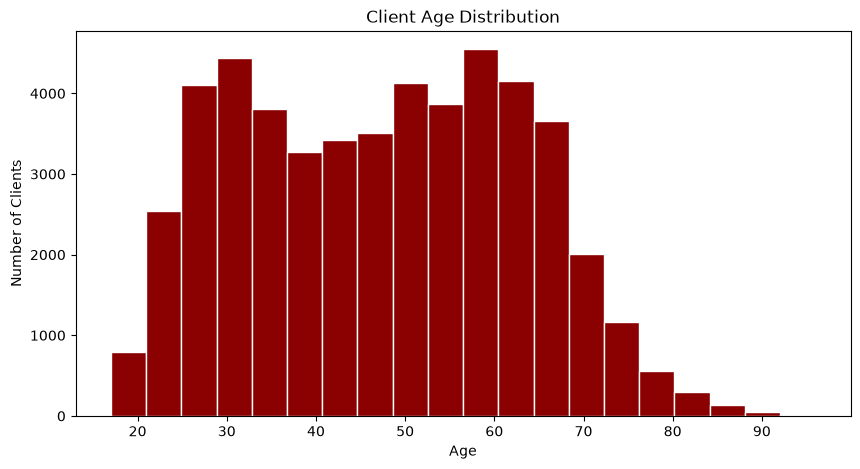

In [21]:
# Visualizing the distribution

plt.figure(figsize=(10, 5))
plt.hist(clients_h2["age"].dropna(), bins=20, color="darkred",edgecolor="white")
plt.title("Client Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Clients")
plt.show()

Looking at the histogram, we can see two peaks around
the ages of 30 and 60.

We can also see that there are fewer clients above
the age of 70.

In [22]:
# Checking the age difference between successful and unsuccessful clients

print("Successful clients:")
display(clients_h2[clients_h2["attempts_to_success"].notna()]["age"].describe().round(2))
print("\nUnsuccessful clients:")
display(clients_h2[clients_h2["attempts_to_success"].isna()]["age"].describe().round(2))

Successful clients:


count    21001.00
mean        44.39
std         14.96
min         17.00
25%         31.50
50%         43.50
75%         56.50
max         94.50
Name: age, dtype: float64


Unsuccessful clients:


count    29486.00
mean        49.41
std         15.57
min         17.50
25%         36.00
50%         51.00
75%         61.50
max         96.00
Name: age, dtype: float64

Clients who successfully completed the process are,
on average, around 5 years younger than clients who
did not succeed.

This is our first indication that age may be related
to the success of the process.

In [23]:
# Investigating the relationship between age and attempts

clients_h2.groupby("attempts_to_success")["age"].agg(["count", "mean", "median"]).round(2)

,count,mean,median
attempts_to_success,,,
1.0,17966,43.84,42.50
2.0,2433,46.95,48.00
3.0,420,50.01,52.00
4.0,116,51.72,53.50
5.0,24,49.12,48.25
6.0,12,57.96,59.50
7.0,14,51.14,54.50
8.0,7,45.07,44.00
9.0,3,49.50,58.00


We can see that the average and median ages increase
from the first to the fourth attempt.

Clients who succeeded on their first attempt have
an average age of 43.84 years, while clients who
needed four attempts have an average age of 51.72 years.

After the fourth attempt, the number of clients
is much smaller, so it is more difficult to compare
the results.

These results suggest that older clients may need
more attempts to successfully complete the process.

In [24]:
# Checking the age groups

clients_h2["age"].describe().round(2)

count    50487.00
mean        47.32
std         15.52
min         17.00
25%         33.50
50%         48.00
75%         59.50
max         96.00
Name: age, dtype: float64

In [25]:
# Checking median age to divide the clients in two groups, older and younger

median_age = clients_h2["age"].median()

print(median_age)

48.0


We decided to use the median age (48 years) to divide
our clients into two groups:

- Younger: clients under 48 years old.
- Older: clients aged 48 or above.

By using the median, we can create two groups with
a similar number of clients.

In [26]:
# Creating a new column separating the clients into younger or older groups

clients_h2["age_category"] = pd.cut(clients_h2["age"], bins=[0, median_age, np.inf], labels=["Younger", "Older"], right=False)

clients_h2["age_category"].value_counts()

age_category
Older      25453
Younger    25034
Name: count, dtype: int64

In [27]:
# Compare attempts results

clients_h2.groupby("age_category", observed=True)["attempts_to_success"].agg(["count", "mean", "median", "std"]).round(3)

,count,mean,median,std
age_category,,,,
Younger,12258,1.149,1.0,0.486
Older,8743,1.250,1.0,0.686


In [28]:
# Calculating success rate by age group
total_clients = clients_h2.groupby("age_category", observed=True)["client_id"].count()

successful_clients = clients_h2.groupby("age_category", observed=True)["attempts_to_success"].count()

success_rate = (successful_clients / total_clients * 100).round(2)

display(success_rate)

success_rate_difference = success_rate["Younger"] - success_rate["Older"]

print(f"\nDifference in success rates: {success_rate_difference:.2f}%")

age_category
Younger    48.97
Older      34.35
dtype: float64


Difference in success rates: 14.62%


In [29]:
# Difference in average attempts

mean_attempts = clients_h2.groupby("age_category", observed=True)["attempts_to_success"].mean()

attempts_difference = ((mean_attempts["Older"] - mean_attempts["Younger"]) / mean_attempts["Younger"] * 100)

print(f"Older clients require {attempts_difference:.2f}% more attempts.")

Older clients require 8.83% more attempts.


### H2 - Preliminary Findings

We divided our clients into two age groups:

- Younger clients: 25,034
- Older clients: 25,453

#### Findings

- Younger successful clients need an average of
  1.149 attempts, while older successful clients
  need an average of 1.250 attempts.

- Older successful clients need around 8.8% more
  attempts to successfully complete the process.

- Both groups have a median of 1 attempt.

- Older successful clients have a higher standard
  deviation (0.686 compared to 0.486), meaning
  there is more variation in the number of attempts
  they need.

- Younger clients have a success rate of 48.97%,
  while older clients have a success rate of 34.35%.

- There is a difference of 14.62 percentage points
  between the two success rates.

#### Preliminary conclusion

Our results suggest that younger clients are more
likely to succeed and need fewer attempts when
they do succeed.

However, we still need to perform a statistical
test to check if the difference in the average
number of attempts is statistically significant.

### Statistical Hypothesis Testing

**H0 (Null hypothesis):** Among successful clients,
younger clients need the same or a higher average
number of attempts than older clients.

**H1 (Alternative hypothesis):** Among successful clients,
younger clients need fewer attempts on average than
older clients.

**Significance level (alpha):** 0.05

We decided to use a one-tailed Welch's t-test because:

- We are comparing the averages of two independent groups.
- The groups have different variances.
- Both groups have a large number of clients.
- We want to test if younger clients need fewer
  attempts, not just if there is a difference.

If the p-value is below 0.05, we will reject
the null hypothesis.

In [30]:
# creating 2 independent samples

younger = clients_h2[clients_h2["age_category"] == "Younger"]["attempts_to_success"].dropna()

older = clients_h2[clients_h2["age_category"] == "Older"]["attempts_to_success"].dropna()

print("Younger clients:", len(younger))
print("Older clients:", len(older))

Younger clients: 12258
Older clients: 8743


In [31]:
from scipy import stats

statistic, p_value = stats.ttest_ind(
    younger,
    older,
    equal_var=False,
    alternative="less"
)

print("Test statistic:", statistic)
print("P-value:", p_value)

Test statistic: -11.858736893280275
P-value: 1.3587794687787136e-32


In [32]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Reject the null hypothesis.


### H2 - Statistical Results and Conclusion

#### Statistical results

- Test statistic: -11.8587
- P-value: 1.3588e-32
- Significance level: 0.05

As our p-value is below 0.05, we reject the null
hypothesis.

#### Conclusion

Our results support our initial hypothesis (H2).

Among successful clients, younger clients need
significantly fewer attempts to successfully
complete the process than older clients.

We also found that younger clients have a higher
success rate.

This suggests that older clients may experience
more difficulties when using Vanguard's digital
platform.

#### Recommendations

Based on our findings, Vanguard could consider:

- Making the navigation simpler.
- Providing clearer instructions.
- Adding step-by-step guidance.
- Making help easier to find during the process.
- Improving accessibility for different age groups.

These improvements could help older clients
complete the process with fewer difficulties.

#### Limitations

Our statistical test only includes clients who
successfully completed the process at least once.

We included unsuccessful clients when calculating
the success rates, but not when calculating the
average number of attempts to success.

We can only analyze the attempts recorded in our
dataset, not the client's entire history with Vanguard.

We used the median age of our dataset to define
younger and older clients.

We did not perform a separate statistical test
on the difference between the success rates.

Although we found a relationship between age and
the number of attempts, we cannot conclude that
age is the cause of these difficulties.

Other factors, such as experience with technology,
client tenure or the interface used, may also
influence the results.